## Model Training

#### 1.1 Import Data and Required Packages
##### Importing Pandas, Numpy, Matplotlib, Seaborn and Warings Library.

In [2]:
# Basic Import
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns
# Modelling
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor,AdaBoostRegressor
from sklearn.svm import SVR
from sklearn.linear_model import LinearRegression, Ridge,Lasso
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.model_selection import RandomizedSearchCV
from catboost import CatBoostRegressor
from xgboost import XGBRegressor
import warnings

#### Import the CSV Data as Pandas DataFrame

In [3]:
df = pd.read_csv("./Data/after_preprocess.csv")

#### Show Top 5 Records

In [4]:
df.head()

,NAME,DIV,DEP,LOC,LEAVE DATE,TYPE,NO DAYS,LEAVE MONTH,LEAVE YEAR,LEAVE DAY OF WEEK,PREV LEAVE DATE,DAYS SINCE LAST LEAVE,NEXT LEAVE DATE,DAYS UNTIL NEXT LEAVE,CUMULATIVE LEAVE COUNT
0,A.A.A.R.DE SILVA,DHA,SAB,SEU,2020-01-31,CS,1.0,1,2020,4,2020-01-11,20.0,2020-02-01,1.0,2
1,A.A.A.R.DE SILVA,DHA,SAB,SEU,2020-02-01,CS,0.5,2,2020,5,2020-01-31,1.0,2020-02-15,14.0,3
2,A.A.A.R.DE SILVA,DHA,SAB,SEU,2020-02-15,AL,0.5,2,2020,5,2020-02-01,14.0,2020-02-18,3.0,4
3,A.A.A.R.DE SILVA,DHA,SAB,SEU,2020-02-18,CS,1.0,2,2020,1,2020-02-15,3.0,2020-03-10,21.0,5
4,A.A.A.R.DE SILVA,DHA,SAB,SEU,2020-03-10,CS,1.0,3,2020,1,2020-02-18,21.0,2020-06-11,93.0,6


In [5]:
df = df.drop(columns=['LEAVE DATE', 'PREV LEAVE DATE', 'NEXT LEAVE DATE'])
df

,NAME,DIV,DEP,LOC,TYPE,NO DAYS,LEAVE MONTH,LEAVE YEAR,LEAVE DAY OF WEEK,DAYS SINCE LAST LEAVE,DAYS UNTIL NEXT LEAVE,CUMULATIVE LEAVE COUNT
0,A.A.A.R.DE SILVA,DHA,SAB,SEU,CS,1.0,1,2020,4,20.0,1.0,2
1,A.A.A.R.DE SILVA,DHA,SAB,SEU,CS,0.5,2,2020,5,1.0,14.0,3
2,A.A.A.R.DE SILVA,DHA,SAB,SEU,AL,0.5,2,2020,5,14.0,3.0,4
3,A.A.A.R.DE SILVA,DHA,SAB,SEU,CS,1.0,2,2020,1,3.0,21.0,5
4,A.A.A.R.DE SILVA,DHA,SAB,SEU,CS,1.0,3,2020,1,21.0,93.0,6
...,...,...,...,...,...,...,...,...,...,...,...,...
232796,Y.S.D.DHARMATHILAKA,DMD,SRC,FIU,SK,1.0,7,2024,1,20.0,60.0,3
232797,Y.S.D.DHARMATHILAKA,DMD,SRC,FIU,DL,0.5,9,2024,5,60.0,11.0,4
232798,Y.S.D.DHARMATHILAKA,DMD,SRC,FIU,CS,1.0,10,2024,2,11.0,5.0,5
232799,Y.S.D.DHARMATHILAKA,DMD,SRC,FIU,SK,1.0,10,2024,0,5.0,1.0,6


#### Preparing X and Y variables

In [6]:
X = df.drop(columns=['DAYS UNTIL NEXT LEAVE'],axis=1)

In [7]:
X.head()

,NAME,DIV,DEP,LOC,TYPE,NO DAYS,LEAVE MONTH,LEAVE YEAR,LEAVE DAY OF WEEK,DAYS SINCE LAST LEAVE,CUMULATIVE LEAVE COUNT
0,A.A.A.R.DE SILVA,DHA,SAB,SEU,CS,1.0,1,2020,4,20.0,2
1,A.A.A.R.DE SILVA,DHA,SAB,SEU,CS,0.5,2,2020,5,1.0,3
2,A.A.A.R.DE SILVA,DHA,SAB,SEU,AL,0.5,2,2020,5,14.0,4
3,A.A.A.R.DE SILVA,DHA,SAB,SEU,CS,1.0,2,2020,1,3.0,5
4,A.A.A.R.DE SILVA,DHA,SAB,SEU,CS,1.0,3,2020,1,21.0,6


In [8]:
y = df['DAYS UNTIL NEXT LEAVE']
y

0          1.0
1         14.0
2          3.0
3         21.0
4         93.0
          ... 
232796    60.0
232797    11.0
232798     5.0
232799     1.0
232800    37.0
Name: DAYS UNTIL NEXT LEAVE, Length: 232801, dtype: float64

#### Identifying categorical and numerical features

In [9]:
# define numerical & categorical columns
numeric_features = [feature for feature in df.columns if df[feature].dtype != 'O']
categorical_features = [feature for feature in df.columns if df[feature].dtype == 'O']

# print columns
print('We have {} numerical features : {}'.format(len(numeric_features), numeric_features))
print('\nWe have {} categorical features : {}'.format(len(categorical_features), categorical_features))

We have 7 numerical features : ['NO DAYS', 'LEAVE MONTH', 'LEAVE YEAR', 'LEAVE DAY OF WEEK', 'DAYS SINCE LAST LEAVE', 'DAYS UNTIL NEXT LEAVE', 'CUMULATIVE LEAVE COUNT']

We have 5 categorical features : ['NAME', 'DIV', 'DEP', 'LOC', 'TYPE']


In [10]:
print("Categories in 'NAME' variable:     ",end=" " )
print(df['NAME'].unique())

print("Categories in 'DIV' variable:  ",end=" ")
print(df['DIV'].unique())

print("Categories in 'DEP' variable:",end=" " )
print(df['DEP'].unique())

print("Categories in 'LOC' variable:     ",end=" " )
print(df['LOC'].unique())

print("Categories in 'TYPE' variable:     ",end=" " )
print(df['TYPE'].unique())

Categories in 'NAME' variable:      ['A.A.A.R.DE SILVA' 'A.A.C.P.AMARASINGHE' 'A.A.D.A.R.AMARASINGHE' ...
 'Y.P.L.R.K. DISSANAYAKE' 'Y.R.A.P.M. RAJAPAKSE' 'Y.S.D.DHARMATHILAKA']
Categories in 'DIV' variable:   ['DHA' 'DPR' 'DYA' 'DBU' 'DMD' 'DMP' 'DFI' 'DPH' 'DPJ' 'DRD' 'DCH' 'DQA'
 'DPE']
Categories in 'DEP' variable: ['SAB' 'SSO' 'SHC' 'SDE' 'SMT' 'SDM' 'SHE' 'SRC' 'SHD' 'SHT' 'SWE' 'SDS'
 'SMO' 'SEA' 'SQC' 'SSC' 'SMG' 'SMP' 'SAC' 'SIR' 'SEM' 'SIT' 'SSR' 'SSM'
 'SYD' 'SMA' 'SLE' 'SFI' 'SIN' 'SPJ' 'SPR' 'SAA' 'SBU' 'SCH' 'SHA' 'SMN'
 'SES' 'SNE' 'SQA' 'SMD' 'SRE']
Categories in 'LOC' variable:      ['SEU' 'COM' 'SWC' 'FIS' 'PPH' 'FIE' 'DOS' 'GAC' 'DFS' 'TRC' 'WTS' 'FIU'
 'PP4' 'SWR' 'MAT' 'BLP' 'KIT' 'DEO' 'MAO' 'MEW' 'SEE' 'ELW' 'ENW' 'MEC'
 'AUW' 'PFS' 'ALW' 'QCO' 'ADU' 'PPM' 'TRA' 'CAL' 'SEC' 'MPO' 'NTS' 'PEO'
 'PAY' 'BLU' 'PE1' 'SCA' 'EST' 'DMO' 'WHA' 'ITO' 'STD' 'SVG' 'WEP' 'STC'
 'FTS' 'MAS' 'KBL' 'WEL' 'SRP' 'YDU' 'SHB' 'WSO' 'LOP' 'MAR' 'PFH' 'PE2'
 'CAR' 'IMP' 'SAF' 'SHR' 'LE

#### Created column transformer pipeline

In [11]:
from sklearn.impute import SimpleImputer

# Create Column Transformer with 3 types of transformers
numerical_columns = ['NO DAYS', 'LEAVE MONTH', 'LEAVE YEAR', 'LEAVE DAY OF WEEK', 'DAYS SINCE LAST LEAVE', 'CUMULATIVE LEAVE COUNT']
categorical_columns = ['NAME', 'DIV', 'DEP', 'LOC', 'TYPE']

from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

num_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")), #handling missing values
        ("scaler", StandardScaler(with_mean=False))
    ]
)

cat_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("one_hot_encoder", OneHotEncoder(handle_unknown='ignore')),
        ("scaler", StandardScaler(with_mean=False))
    ]
)

preprocessor = ColumnTransformer([
    ("num_pipeline", num_pipeline, numerical_columns),
    ("cat_pipeline", cat_pipeline, categorical_columns)
])

In [12]:
X = preprocessor.fit_transform(X)

In [13]:
X.shape

(232801, 1689)

#### Splitting data to test and train

In [14]:
# separate dataset into train and test
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)
X_train.shape, X_test.shape

((186240, 1689), (46561, 1689))

#### Create an Evaluate Function to give all metrics after model Training

In [15]:
def evaluate_model(true, predicted):
    mae = mean_absolute_error(true, predicted)
    mse = mean_squared_error(true, predicted)
    rmse = np.sqrt(mean_squared_error(true, predicted))
    r2_square = r2_score(true, predicted)
    return mae, rmse, r2_square

#### Hyperparameter Tuning 

In [25]:
from sklearn.model_selection import GridSearchCV

# Define models and parameters
models = {
    "Linear Regression": LinearRegression(),
    "Lasso": Lasso(),
    "Ridge": Ridge(),
    "K-Neighbors Regressor": KNeighborsRegressor(),
    "Decision Tree": DecisionTreeRegressor(),
    "Random Forest Regressor": RandomForestRegressor(),
    "XGBRegressor": XGBRegressor(),
    "CatBoosting Regressor": CatBoostRegressor(verbose=False),
    "AdaBoost Regressor": AdaBoostRegressor()
}

params = {
    "Decision Tree": {
        'criterion': ['squared_error', 'friedman_mse', 'absolute_error']
    },
    "Random Forest": {
        'n_estimators': [8, 16, 32, 64, 128, 256]
    },
    "Gradient Boosting": {
        'learning_rate': [0.1, 0.01, 0.05, 0.001],
        'subsample': [0.6, 0.7, 0.75, 0.8, 0.85, 0.9],
        'n_estimators': [8, 16, 32, 64, 128, 256]
    },
    "Linear Regression": {},
    "XGBRegressor": {
        'learning_rate': [0.1, 0.01, 0.05, 0.001],
        'n_estimators': [8, 16, 32, 64, 128, 256]
    },
    "CatBoosting Regressor": {
        'depth': [6, 8],
        'learning_rate': [0.01, 0.05, 0.1, 0.6],
        'iterations': [30, 50, 100]
    },
    "AdaBoost Regressor": {
        'learning_rate': [0.1, 0.01, 0.5, 0.001],
        'n_estimators': [8, 16, 32, 64, 128, 256]
    }
}

model_list = []
best_params_list = []
r2_list = []

# Loop through each model
for model_name, model in models.items():
    print(f"Processing {model_name}...")
    param = params.get(model_name, {})  # Get params for the current model

    # Perform GridSearchCV if parameters are available
    if param:
        grid_search = GridSearchCV(estimator=model, param_grid=param, cv=3, scoring='r2', verbose=1, error_score=np.nan)
        grid_search.fit(X_train, y_train)
        best_model = grid_search.best_estimator_
        best_params = grid_search.best_params_
    else:
        # Fit without GridSearchCV if no parameters are defined
        best_model = model
        best_model.fit(X_train, y_train)
        best_params = "Default parameters"

    # Evaluate the best model
    y_train_pred = best_model.predict(X_train)
    y_test_pred = best_model.predict(X_test)
    
    model_train_mae, model_train_rmse, model_train_r2 = evaluate_model(y_train, y_train_pred)
    model_test_mae, model_test_rmse, model_test_r2 = evaluate_model(y_test, y_test_pred)
    
    # Append results
    model_list.append(model_name)
    best_params_list.append(best_params)
    r2_list.append(model_test_r2)
    
    # Print results
    print(f"{model_name} - Best Parameters: {best_params}")
    print('Model performance for Test set')
    print("- Root Mean Squared Error: {:.4f}".format(model_test_rmse))
    print("- Mean Absolute Error: {:.4f}".format(model_test_mae))
    print("- R2 Score: {:.4f}".format(model_test_r2))
    print("=" * 50)

Processing Linear Regression...
Linear Regression - Best Parameters: Default parameters
Model performance for Test set
- Root Mean Squared Error: 13.3902
- Mean Absolute Error: 7.8783
- R2 Score: 0.0725
Processing Lasso...
Lasso - Best Parameters: Default parameters
Model performance for Test set
- Root Mean Squared Error: 13.7530
- Mean Absolute Error: 8.1985
- R2 Score: 0.0216
Processing Ridge...
Ridge - Best Parameters: Default parameters
Model performance for Test set
- Root Mean Squared Error: 13.3902
- Mean Absolute Error: 7.8783
- R2 Score: 0.0725
Processing K-Neighbors Regressor...


KeyboardInterrupt: 

#### Single model training

In [16]:
lin_model = XGBRegressor(n_estimators=230, learning_rate=0.091, max_depth=18, random_state=42)
lin_model = lin_model.fit(X_train, y_train)
y_pred = lin_model.predict(X_test)
model_test_mae, model_test_rmse, model_test_r2 = evaluate_model(y_test, y_pred)
# score = r2_score(y_test, y_pred)*100 
print(" r2 score of the model is %.2f" %model_test_r2)
print(" mae score of the model is %.2f" %model_test_mae)

 r2 score of the model is 0.11
 mae score of the model is 7.53


#### Custom date accuracy function

In [17]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Define a custom accuracy function
def custom_date_accuracy(y_true, y_pred, tolerance=14):
    """
    Calculate the percentage of predictions within the given tolerance range.
    Args:
        y_true (array-like): True target values.
        y_pred (array-like): Predicted target values.
        tolerance (int): Number of days for the acceptable range (default is ±14 days).
    Returns:
        float: Accuracy as a percentage.
    """
    # Ensure inputs are numpy arrays
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    
    # Calculate the absolute difference in days
    differences = np.abs(y_pred - y_true)
    
    # Check how many predictions fall within the tolerance range
    within_tolerance = np.sum(differences <= tolerance)
    
    # Calculate accuracy as a percentage
    accuracy = (within_tolerance / len(y_true)) * 100
    return accuracy

# Evaluate the CatBoost model with the custom accuracy metric
lin_model = XGBRegressor(n_estimators=200, learning_rate=0.091, max_depth=18, random_state=42)
lin_model.fit(X_train, y_train)
y_pred = lin_model.predict(X_test)

# Custom accuracy
tolerance_in_days = 4  # Define the tolerance range (±14 days)
date_accuracy = custom_date_accuracy(y_test, y_pred, tolerance=tolerance_in_days)

# Print the results
print(f"Custom Date Accuracy (±{tolerance_in_days} days): {date_accuracy:.2f}%")

Custom Date Accuracy (±4 days): 39.90%


#### Plotting predictions vs true values

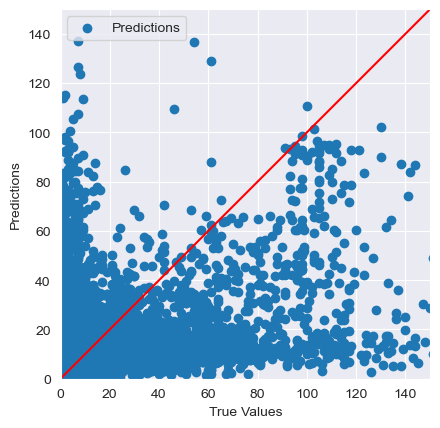

In [18]:
ax = plt.axes(aspect="equal")
plt.scatter(y_test, y_pred, label="Predictions")
plt.xlabel("True Values")
plt.ylabel("Predictions")
lims = [0,150]
plt.xlim(lims)
plt.ylim(lims)
plt.legend()
_ = plt.plot(lims, lims, c="red")

In [19]:
import os 
import sys
import numpy as np
import pandas as pd
import pickle
#from src.exception import CustomException
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import r2_score

#### Function to save objects 

In [20]:
def save_object(file_path, obj):
    dir_path = os.path.dirname(file_path)

    os.makedirs(dir_path, exist_ok=True)

    with open(file_path, "wb") as file_obj:
        pickle.dump(obj, file_obj)


#### Saving the pre-processor

In [23]:
save_object(
    file_path="./savedObj/preprocessor.pkl",
    obj=preprocessor
)

#### Saving the model

In [24]:
save_object(
    file_path="./savedObj/model.pkl",
    obj=lin_model
)

#### Function to load objects

In [25]:
def load_object(file_path):
    with open(file_path, "rb") as file_obj:
        return pickle.load(file_obj)

#### Loading the saved files

In [26]:
preprocessor_path = './savedObj/preprocessor.pkl'
model_path = './savedObj/model.pkl'
model = load_object(file_path=model_path)
preprocessor = load_object(file_path=preprocessor_path)

#### Reading the dataset with no next leave date

In [32]:
no_next_leave_date = pd.read_csv('./Data/data_without_next_leave.csv')
no_next_leave_date

,NAME,DIV,DEP,LOC,LEAVE DATE,TYPE,NO DAYS,LEAVE MONTH,LEAVE YEAR,LEAVE DAY OF WEEK,PREV LEAVE DATE,DAYS SINCE LAST LEAVE,NEXT LEAVE DATE,DAYS UNTIL NEXT LEAVE,CUMULATIVE LEAVE COUNT
0,A.A.A.R.DE SILVA,DHA,SAB,SEU,2024-12-31,AL,1.0,12,2024,1,2024-12-24,7.0,NaN,NaN,26
1,A.A.C.P.AMARASINGHE,DPR,SSO,COM,2024-12-31,AL,1.0,12,2024,1,2024-12-30,1.0,NaN,NaN,39
2,A.A.D.A.R.AMARASINGHE,DPR,SHC,SWC,2024-11-14,DL,0.5,11,2024,3,2024-10-29,16.0,NaN,NaN,52
3,A.A.D.C.B.AMARASINGHE,DPR,SDE,FIS,2024-12-21,AL,0.5,12,2024,5,2024-12-20,1.0,NaN,NaN,18
4,A.A.D.JEEWANTHA,DYA,SMT,PPH,2024-12-13,CS,1.0,12,2024,4,2024-12-07,6.0,NaN,NaN,48
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1514,Y.M.S. DILSHAN,DPR,SSO,ALW,2024-12-24,CS,1.0,12,2024,1,2024-12-23,1.0,NaN,NaN,47
1515,Y.P.L.M.DHARMARATNA,DPR,SDE,DFS,2024-12-31,CS,0.5,12,2024,1,2024-12-28,3.0,NaN,NaN,44
1516,Y.P.L.R.K. DISSANAYAKE,DHA,SWE,TRA,2024-11-30,AL,0.5,11,2024,5,2024-11-14,16.0,NaN,NaN,11
1517,Y.R.A.P.M. RAJAPAKSE,DBU,SSM,AFR,2024-12-28,AL,0.5,12,2024,5,2024-12-27,1.0,NaN,NaN,49


#### Dropping the unnecessary columns of the dataset

In [33]:
df = no_next_leave_date.drop(columns=['LEAVE DATE', 'PREV LEAVE DATE', 'NEXT LEAVE DATE', 'DAYS UNTIL NEXT LEAVE'])
df

,NAME,DIV,DEP,LOC,TYPE,NO DAYS,LEAVE MONTH,LEAVE YEAR,LEAVE DAY OF WEEK,DAYS SINCE LAST LEAVE,CUMULATIVE LEAVE COUNT
0,A.A.A.R.DE SILVA,DHA,SAB,SEU,AL,1.0,12,2024,1,7.0,26
1,A.A.C.P.AMARASINGHE,DPR,SSO,COM,AL,1.0,12,2024,1,1.0,39
2,A.A.D.A.R.AMARASINGHE,DPR,SHC,SWC,DL,0.5,11,2024,3,16.0,52
3,A.A.D.C.B.AMARASINGHE,DPR,SDE,FIS,AL,0.5,12,2024,5,1.0,18
4,A.A.D.JEEWANTHA,DYA,SMT,PPH,CS,1.0,12,2024,4,6.0,48
...,...,...,...,...,...,...,...,...,...,...,...
1514,Y.M.S. DILSHAN,DPR,SSO,ALW,CS,1.0,12,2024,1,1.0,47
1515,Y.P.L.M.DHARMARATNA,DPR,SDE,DFS,CS,0.5,12,2024,1,3.0,44
1516,Y.P.L.R.K. DISSANAYAKE,DHA,SWE,TRA,AL,0.5,11,2024,5,16.0,11
1517,Y.R.A.P.M. RAJAPAKSE,DBU,SSM,AFR,AL,0.5,12,2024,5,1.0,49


#### Scaling the data using the preprocessor

In [34]:
data_scaled = preprocessor.transform(df)
data_scaled

<1519x1689 sparse matrix of type '<class 'numpy.float64'>'
	with 16479 stored elements in Compressed Sparse Row format>

#### predicting the 'DAYS UNTIL NEXT LEAVE'

In [35]:
preds = model.predict(data_scaled)
preds

array([ 4.9211226,  3.1312776, 12.049293 , ..., 12.447258 , 10.5591545,
        7.890455 ], dtype=float32)

#### saving the predictions as a new column

In [39]:
no_next_leave_date['DAYS UNTIL NEXT LEAVE'] = preds
no_next_leave_date.head(5)

,NAME,DIV,DEP,LOC,LEAVE DATE,TYPE,NO DAYS,LEAVE MONTH,LEAVE YEAR,LEAVE DAY OF WEEK,PREV LEAVE DATE,DAYS SINCE LAST LEAVE,NEXT LEAVE DATE,DAYS UNTIL NEXT LEAVE,CUMULATIVE LEAVE COUNT
0,A.A.A.R.DE SILVA,DHA,SAB,SEU,2024-12-31,AL,1.0,12,2024,1,2024-12-24,7.0,NaN,4.921123,26
1,A.A.C.P.AMARASINGHE,DPR,SSO,COM,2024-12-31,AL,1.0,12,2024,1,2024-12-30,1.0,NaN,3.131278,39
2,A.A.D.A.R.AMARASINGHE,DPR,SHC,SWC,2024-11-14,DL,0.5,11,2024,3,2024-10-29,16.0,NaN,12.049293,52
3,A.A.D.C.B.AMARASINGHE,DPR,SDE,FIS,2024-12-21,AL,0.5,12,2024,5,2024-12-20,1.0,NaN,3.202305,18
4,A.A.D.JEEWANTHA,DYA,SMT,PPH,2024-12-13,CS,1.0,12,2024,4,2024-12-07,6.0,NaN,6.116724,48


0     4
1     3
2    12
3     3
4     6
Name: DAYS UNTIL NEXT LEAVE, dtype: int32